In [9]:
# read text into python, make everything lowercase, remove punctuation (~10s)
def getText():
    valid = 'abcdefghijklmnopqrstuvwxyz '
    with open("AllCombined.txt") as f:
        raw = f.read()
    low = raw.lower().replace("\n", " ")
    letters_only = ''.join(char for char in low if char in valid)
    return letters_only

txt = getText()
print(txt[:500])

 april  april apr is the fourth month of the year in the julian and gregorian calendars and comes between march and may it is one of four months to have  days  april always begins on the same day of the week as july and additionally january in leap years april always ends on the same day of the week as december  april comes between march and may making it the fourth month of the year it also comes first in the year out of the four months that have  days as june september and november are later i


In [10]:
import cupy as np
import numpy as onp

In [11]:
# tokenize and build vocab
from collections import Counter
vocab_sz = 10000
stop_words = ["i", "me", "my", "myself", "we", "our", "ours", "ourselves", "you", "your", "yours", "yourself", "yourselves", "he", "him", "his", "himself", "she", "her", "hers", "herself", "it", "its", "itself", "they", "them", "their", "theirs", "themselves", "what", "which", "who", "whom", "this", "that", "these", "those", "am", "is", "are", "was", "were", "be", "been", "being", "have", "has", "had", "having", "do", "does", "did", "doing", "a", "an", "the", "and", "but", "if", "or", "because", "as", "until", "while", "of", "at", "by", "for", "with", "about", "against", "between", "into", "through", "during", "before", "after", "above", "below", "to", "from", "up", "down", "in", "out", "on", "off", "over", "under", "again", "further", "then", "once", "here", "there", "when", "where", "why", "how", "all", "any", "both", "each", "few", "more", "most", "other", "some", "such", "no", "nor", "not", "only", "own", "same", "so", "than", "too", "very", "s", "t", "can", "will", "just", "don", "should", "now"]

lst = [word for word in txt.split() if word != '']
filtered = [word for word in lst if word not in stop_words]

def build_vocab(vsz):
    global vocab, vocab_sz, vocab_st, dict, data
    vocab = [word for word, cnt in Counter(filtered).most_common(vsz) if word not in stop_words]
    vocab_sz = len(vocab)
    vocab_st = set(vocab)
    dict = {word: i for i, word in enumerate(vocab)}
    data = [dict[word] for word in filtered if word in vocab_st]

build_vocab(3000)
print(len(data))

10671628


In [12]:
# training data, loop over the text to generate target and context
# import numpy as np
import Neural as Neur
np.random.seed(400)

def get_training_data(window):
    global X_train, Y_train, X_test, Y_test, sz
    x = []
    y = []
    # window = 10
    for i in range(window, len(data) - window):
        start = i - window
        end = i + window + 1
        context = []
        for j in range(start, end):
            if i != j:
                context.append(data[j])
        x.append(context)
        y.append(data[i])
    
    
    x = np.array(x)
    y = np.array(y)
    indices = np.arange(len(x))
    np.random.shuffle(indices)
    x_shuffled = x[indices]
    y_shuffled = y[indices]
    end = int(len(x_shuffled) * 0.9)
    
    X_train = x_shuffled[:end]
    Y_train = y_shuffled[:end]
    X_test = x_shuffled[end:]
    Y_test = y_shuffled[end:]
    sz = len(Y_train)
    print(sz)



In [13]:
# neural network!
import importlib
from tqdm import tqdm
import cupyx
importlib.reload(Neur)

def get_cbow(context):
    ctx = np.asarray(context)
    mat = np.zeros((len(ctx), vocab_sz), dtype=np.float32)
    rows = np.repeat(np.arange(len(ctx)), ctx.shape[1])
    cupyx.scatter_add(mat, (rows, ctx.ravel()), np.float32(1.0 / (2 * window)))
    return mat

def get_one_hot(indices):
    mat = np.zeros((len(indices), vocab_sz), dtype=np.float32)
    mat[np.arange(len(indices)), indices] = 1
    return mat



In [8]:
def run_simlex_benchmark(filepath, norm_embed):
    simlex, model = [], []

    with open(filepath, 'r') as f:
        next(f)
        for line in f:
            parts = line.strip().lower().split('\t')

            if len(parts) >= 4 and parts[0] in vocab_st and parts[1] in vocab_st:
                simlex.append(float(parts[3]))
                cos_sim = onp.dot(norm_embed[dict[parts[0]]], norm_embed[dict[parts[1]]])
                model.append(cos_sim)

    # spearman rank correlation
    n = len(simlex)
    d_sq = (onp.argsort(onp.argsort(simlex)) - onp.argsort(onp.argsort(model))) ** 2
    res = 1 - (6 * np.sum(d_sq)) / (n * (n ** 2 - 1))

    """
    print("Simlex999 benchmark:")
    print(f"Data size: {n}")
    print(f"Spearman's Rho: {res:.4f}\n")
    """
    return res

def run_wordsim_benchmark(filepath, norm_embed):
    wordsim, model = [], []

    with open(filepath, 'r') as f:
        next(f)
        for line in f:
            parts = line.strip().lower().split(',')

            if len(parts) >= 3 and parts[0] in vocab_st and parts[1] in vocab_st:
                wordsim.append(float(parts[2]))
                cos_sim = onp.dot(norm_embed[dict[parts[0]]], norm_embed[dict[parts[1]]])
                model.append(cos_sim)

    # spearman rank correlation
    n = len(wordsim)
    d_sq = (onp.argsort(onp.argsort(wordsim)) - onp.argsort(onp.argsort(model))) ** 2
    res = 1 - (6 * np.sum(d_sq)) / (n * (n ** 2 - 1))

    """
    print("WordSim353 benchmark:")
    print(f"Data size: {n}")
    print(f"Spearman's Rho: {res:.4f}\n")
    """
    return res

def run_google_benchmark(path, norm_embed):
    tests = []
    valid = 0
    with open(path, 'r') as f:
        for line in f:
            line = line.strip().lower()
            words = line.split()
            if len(words) == 4 and all(w in vocab_st for w in words):
                tests.append(tuple(words))
                valid += 1

    top1, top3, top5 = 0, 0, 0
    
    for (a, b, c, ans) in tests:
        vec_a = norm_embed[dict[a]]
        vec_b = norm_embed[dict[b]]
        vec_c = norm_embed[dict[c]]

        target = vec_b - vec_a + vec_c
        target = target / onp.linalg.norm(target)
        similar = norm_embed @ target
        similar[dict[a]] = -100
        similar[dict[b]] = -100
        similar[dict[c]] = -100
        nearest = onp.argsort(similar)[::-1]

        best_words1 = [vocab[idx] for idx in nearest[:1]]
        best_words3 = [vocab[idx] for idx in nearest[:3]]
        best_words5 = [vocab[idx] for idx in nearest[:5]]

        if ans in best_words1:
            top1 += 1
        if ans in best_words3:
            top3 += 1
        if ans in best_words5:
            top5 += 1

    acc1 = (top1 / valid) * 100
    acc3 = (top3 / valid) * 100
    acc5 = (top5 / valid) * 100

    # return acc1
    """
    print("Google benchmark:")
    print(f"Top-1 Accuracy: {top1}/{valid} ({acc1:.2f}%)")
    print(f"Top-{k} Accuracy: {topk}/{valid} ({acck:.2f}%)\n")
    """
    return acc1, acc3, acc5

"""
for optim3 in optimizers:
    best = int(onp.argmin(test_losses[optim3]))
    print(best)
    embed2 = networks[optim3][best].list_layers[0].A.T.get()
    # embed2 = networks[optim3][4].list_layers[0].A.T.get()
    norms2 = onp.linalg.norm(embed2, axis=1, keepdims=True)
    norm_embed2 = embed2 / norms2
    print(f"===== {optim3} =====")
    run_simlex_benchmark("SimLex-999.txt", norm_embed2)
    run_wordsim_benchmark("wordsim353crowd.csv", norm_embed2)
    run_google_benchmark("questions-words.txt", norm_embed2, k=3)
    run_google_benchmark("questions-words.txt", norm_embed2, k=5)
"""

'\nfor optim3 in optimizers:\n    best = int(onp.argmin(test_losses[optim3]))\n    print(best)\n    embed2 = networks[optim3][best].list_layers[0].A.T.get()\n    # embed2 = networks[optim3][4].list_layers[0].A.T.get()\n    norms2 = onp.linalg.norm(embed2, axis=1, keepdims=True)\n    norm_embed2 = embed2 / norms2\n    print(f"===== {optim3} =====")\n    run_simlex_benchmark("SimLex-999.txt", norm_embed2)\n    run_wordsim_benchmark("wordsim353crowd.csv", norm_embed2)\n    run_google_benchmark("questions-words.txt", norm_embed2, k=3)\n    run_google_benchmark("questions-words.txt", norm_embed2, k=5)\n'

In [9]:
import time
import copy

def step_sgd(N_a, state, g):
    params = N_a.get_params()
    N_a.set_params(params - state['lr'] * g)
    
    state['track'].append(state['lr'])
    return state

def get_mat(N_a, d):
    d1 = N_a.list_layers[0].list_layers[0]
    dim, V = d1.n_sortie, d1.n_entree
    vdot = d[:dim * V].reshape(dim, V)
    b1 = d[dim * V: dim * V + dim]
    udot = d[dim * V + dim: dim * V * 2 + dim].reshape(V, dim)
    b2 = d[dim * V * 2 + dim:]
    return vdot, b1, udot, b2

def curvature(N_a, d):
    N = N_a.list_layers[0]
    l1, l2, loss = N.list_layers[0], N.list_layers[1], N_a.list_layers[1]
    h = l2.save_X
    z = loss.save_X
    xin = l1.save_X
    tar = loss.save_D
    u = l2.A
    vdot, b1, udot, b2 = get_mat(N_a, d)
    
    hdot = vdot @ xin + b1[:, None]
    zdot = udot @ h + u @ hdot + b2[:, None]
    zmax = np.max(z, axis=0)
    p = np.exp(z - zmax)
    p /= np.sum(p, axis=0)
    mu = np.sum(p * zdot, axis=0)
    S = np.sum(p * zdot**2, axis=0)
    gdot = udot.T @ (p - tar)
    kappa = (S - mu**2) + 2.0 * np.sum(gdot * hdot, axis=0)
    return kappa

def step_red(N_a, state, g, lv, X):
    beta3, ell, eps = 0.9, 1.0, 1e-4
    
    p = N_a.get_params()
    d = g
    nrm2 = np.dot(d, d)

    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - ell * rk * d)
    state['k'] += 1
    return state

def step_adam(N_a, state, g):
    b1, b2, e = 0.9, 0.999, 1e-8

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * g**2
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))

    p = N_a.get_params()
    p -= state['lr'] * mh / (np.sqrt(vh) + e)
    N_a.set_params(p)
    state['k'] += 1
    return state

def step_adahessian(N_a, state, g, loss_layer, X, Y):
    b1, b2, e, eps = 0.9, 0.999, 1e-4, 1e-3
    p = N_a.get_params()
    z = np.random.choice([-1.0, 1.0], size=len(p)).astype(np.float32)
    N_a.set_params(p + eps * z)
    loss_layer.save_D = Y.T
    N_a.forward(X.T)
    gp, _ = N_a.backward(None)

    N_a.set_params(p)
    D = z * (gp - g) / eps
    D = np.clip(D, -2.0, 2.0)

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * (D**2)
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))

    p -= state['lr'] * mh / (np.sqrt(vh) + e)
    N_a.set_params(p)
    state['k'] += 1
    return state

def step_redm(N_a, state, g, lv, X):
    beta3, b1, ell, eps = 0.9, 0.9, 1.0, 1e-4
    
    p = N_a.get_params()
    state['m'] = b1 * state['m'] + (1 - b1) * g
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    d = mh
    nrm2 = np.dot(d, d)
    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - ell * rk * d)
    state['k'] += 1
    return state

def step_redhessian(N_a, state, g, loss_layer, X, Y):
    b1, b2, beta3, ell, e, eps = 0.9, 0.999, 0.9, 1.0, 1e-4, 1e-3
    p = N_a.get_params()
    z = np.random.choice([-1.0, 1.0], size=len(p)).astype(np.float32)
    N_a.set_params(p + eps * z)
    loss_layer.save_D = Y.T
    N_a.forward(X.T)
    gp, _ = N_a.backward(None)

    N_a.set_params(p)
    N_a.forward(X.T)
    D = z * (gp - g) / eps
    D = np.clip(D, -2.0, 2.0)

    state['m'] = b1 * state['m'] + (1 - b1) * g
    state['v'] = b2 * state['v'] + (1 - b2) * (D**2)
    mh = state['m'] / (1 - b1 ** (state['k'] + 1))
    vh = state['v'] / (1 - b2 ** (state['k'] + 1))
    d = mh / (np.sqrt(vh) + e)

    nrm2 = np.dot(d, d)
    kappa = curvature(N_a, d)
    ck = max(float(np.mean(np.abs(kappa))) / nrm2, 1e-20)
    
    state['chat'] = beta3 * state['chat'] + (1 - beta3) * ck
    ctilde = state['chat'] / (1 - beta3 ** (state['k'] + 1))
    Lk = max(ctilde, ck)
    rk = np.dot(d, g) / (2 * nrm2 * Lk)

    step = ell * rk * d
    snorm = float(np.sqrt(np.dot(step, step)))
    if snorm > 5.0:
        step = step * (5.0 / snorm)

    l1, l2 = N_a.list_layers[0].list_layers[0], N_a.list_layers[0].list_layers[1]
    B = float(max(np.linalg.norm(l1.A, axis=0).max(), np.linalg.norm(l2.A, axis=1).max()))
    state['track'].append((float(np.mean(kappa) / nrm2), B, float(rk)))
    
    N_a.set_params(p - step)
    state['k'] += 1
    return state

In [10]:
def eval_test_loss(N):
    batch = 8192
    loss_layer = Neur.Ilogit_and_KL(None)
    N_a = Neur.Network([N, loss_layer])

    total_loss = 0
    batches = 0

    for k in range(0, len(X_test), batch):
        X_cur = get_cbow(X_test[k:k+batch])
        Y_cur = get_one_hot(Y_test[k:k+batch])

        loss_layer.save_D = Y_cur.T
        loss = N_a.forward(X_cur.T)

        total_loss += loss
        batches += 1

    avg = total_loss / batches
    return avg

def build_net(optimizer, dim, epochs, batch, lr=1.0, decay=1.0):
    np.random.seed(3000)
    history = []
    history_00 = []
    Nh = []

    N = Neur.Network([Neur.Dense(vocab_sz, dim), Neur.Dense(dim, vocab_sz)])
    loss_layer = Neur.Ilogit_and_KL(None)
    N_a = Neur.Network([N, loss_layer])

    state = {'k': 0, 'lr': lr, 'decay': decay, 'track':[]}
    if optimizer in ['adahessian', 'adam', 'redm', 'redhessian']:
        state['m'] = np.zeros(N_a.nb_params, dtype=np.float32)
    if optimizer in ['adahessian', 'adam', 'redhessian']:
        state['v'] = np.zeros(N_a.nb_params, dtype=np.float32)
    if optimizer in ['red', 'redm', 'redhessian']:
        state['chat'] = 0.0

    start_time = time.time()
    times = []
    results = {'test_loss': [], 'google1': [], 'google3': [], 'google5': [], 'wordsim': [], 'simlex': []}

    for epoch in range(epochs):
        total_loss = 0
        indices = np.arange(sz)
        np.random.shuffle(indices)
        X_shuffled = X_train[indices]
        Y_shuffled = Y_train[indices]
        batch_loop = tqdm(range(0, len(X_shuffled), batch),
                          desc=f"Epoch {epoch + 1}/{epochs}",
                          unit="batch")

        batches = 0

        for i in batch_loop:

            X_cur = get_cbow(X_shuffled[i:i+batch])
            Y_cur = get_one_hot(Y_shuffled[i:i+batch])

            loss_layer.save_D = Y_cur.T
            loss = N_a.forward(X_cur.T)
            total_loss += loss
            grads, in_grad = N_a.backward(None)

            gnorm = np.sqrt(np.dot(grads, grads))
            if gnorm > 5.0:
                grads = grads * (5.0 / gnorm)
            
            # history_00.append(grads[0])

            if optimizer == 'sgd':
                state = step_sgd(N_a, state, grads)
            if optimizer == 'red':
                state = step_red(N_a, state, grads, loss, X_cur)
            if optimizer == 'redm':
                state = step_redm(N_a, state, grads, loss, X_cur)
            if optimizer == 'adam':
                state = step_adam(N_a, state, grads)
            if optimizer == 'adahessian':
                state = step_adahessian(N_a, state, grads, loss_layer, X_cur, Y_cur)
            if optimizer == 'redhessian':
                state = step_redhessian(N_a, state, grads, loss_layer, X_cur, Y_cur)

            batches += 1

            if i % 50 == 0:
                batch_loop.set_postfix({"loss": f"{total_loss / batches:.2f}"})

        avg_loss = float(total_loss / batches)
        history.append(avg_loss)

        state['lr'] *= state['decay']
        times.append(time.time() - start_time)
        for layer in N.list_layers:
            layer.save_X = None
        # Nh.append(copy.deepcopy(N))

        results['test_loss'].append(eval_test_loss(N))
        
        embed = N.list_layers[0].A.T.get()
        norms = onp.linalg.norm(embed, axis=1, keepdims=True)
        norm_embed = embed / norms
        
        g1, g3, g5 = run_google_benchmark("questions-words.txt", norm_embed)
        results['google1'].append(g1)
        results['google3'].append(g3)
        results['google5'].append(g5)
        results['wordsim'].append(run_wordsim_benchmark("wordsim353crowd.csv", norm_embed))
        results['simlex'].append(run_simlex_benchmark("SimLex-999.txt", norm_embed))

    return results, history, state['track'], times

In [11]:
import matplotlib.pyplot as plt
import itertools
import pickle

results = {}
loss_history = {}
grad_history = {}
runtime = {}

optimizers = ['adam', 'redhessian', 'redm', 'red', 'adahessian', 'sgd']
windows = [3, 5, 10]
latent_dim = [300, 500, 1000]
vocab_szs = [3000, 5000, 10000]

lr = {'sgd': 3.0, 'adahessian': 0.1, 'adam': 0.01}
for cur_vocab_sz in vocab_szs:
    build_vocab(cur_vocab_sz)
    for window in windows:
        get_training_data(window)
        for optim in optimizers:
            for dim in latent_dim:
                params = (optim, window, dim, cur_vocab_sz)
                print(f"Optimizer: {optim}, Window size: {window}, Dimension: {dim}, Vocab Size: {cur_vocab_sz}")
                if optim == 'sgd':
                    results[params], loss_history[params], grad_history[params], runtime[params] = build_net(optim, dim, 10, 8192, 4.0, 0.95)
                elif optim == 'red' or optim == 'redm' or optim == 'redhessian':
                    results[params], loss_history[params], grad_history[params], runtime[params] = build_net(optim, dim, 10, 8192)
                else:
                    results[params], loss_history[params], grad_history[params], runtime[params] = build_net(optim, dim, 10, 8192, lr[optim])

                with open("sweep_results.pkl", "wb") as f:
                    pickle.dump({
                        'results': results,
                        'loss_history': loss_history,
                        'grad_history': grad_history,
                        'runtime': runtime
                    }, f)

9604459
Optimizer: adam, Window size: 3, Dimension: 300, Vocab Size: 3000


Epoch 10/10: 100%|██████████| 1173/1173 [00:11<00:00, 101.52batch/s, loss=5.57]


Optimizer: adam, Window size: 3, Dimension: 500, Vocab Size: 3000


Epoch 10/10: 100%|██████████| 1173/1173 [00:12<00:00, 91.86batch/s, loss=5.54]


Optimizer: adam, Window size: 3, Dimension: 1000, Vocab Size: 3000


...

Epoch 10/10: 100%|██████████| 1463/1463 [01:18<00:00, 18.66batch/s, loss=7.85]


Optimizer: red, Window size: 10, Dimension: 1000, Vocab Size: 10000


Epoch 10/10: 100%|██████████| 1463/1463 [01:42<00:00, 14.30batch/s, loss=8.16]


Optimizer: adahessian, Window size: 10, Dimension: 300, Vocab Size: 10000


Epoch 4/10:  93%|█████████▎| 1356/1463 [01:25<00:06, 16.06batch/s, loss=6.25]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Epoch 10/10: 100%|██████████| 1463/1463 [01:06<00:00, 21.86batch/s, loss=7.47]


In [14]:
import pickle
import matplotlib.pyplot as plt
with open ("sweep_results.pkl", "rb") as f:
    data = pickle.load(f)

results = data['results']
loss_history = data['loss_history']
runtime = data['runtime']

done


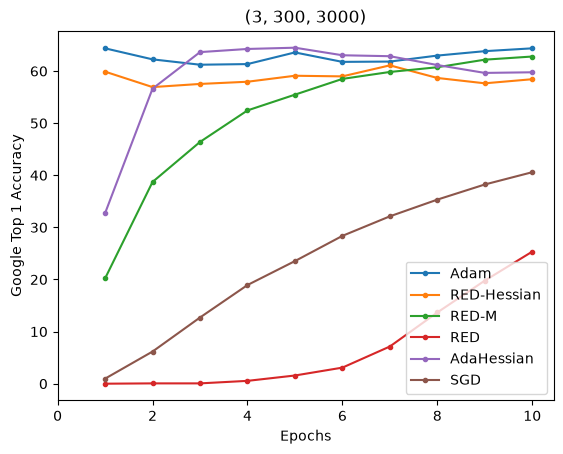

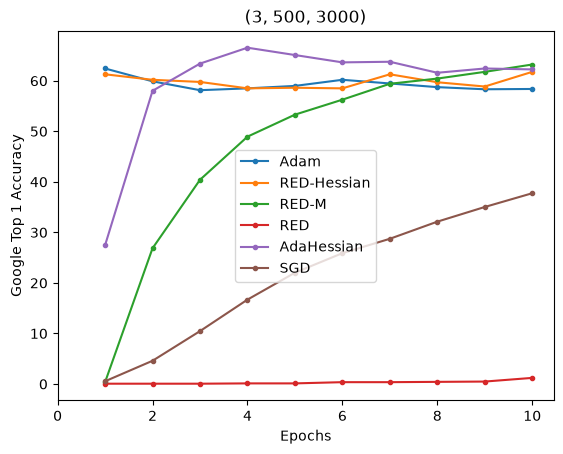

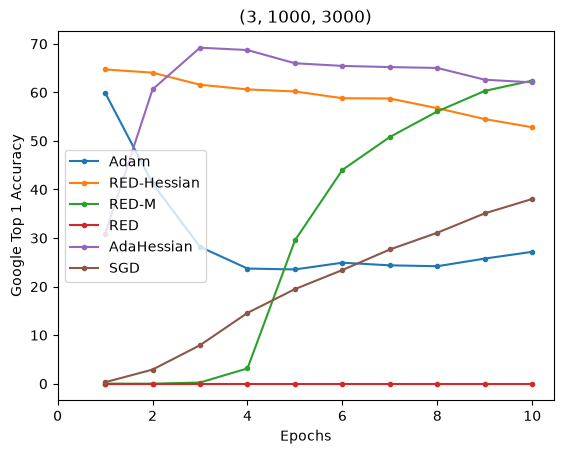

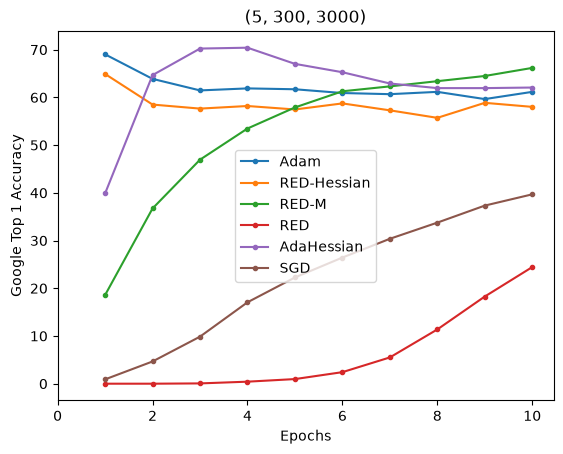

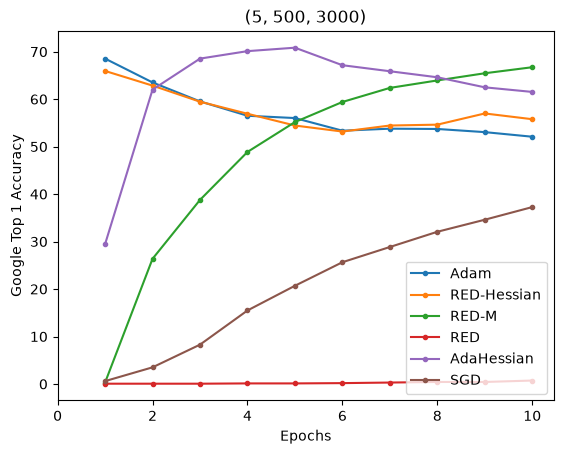

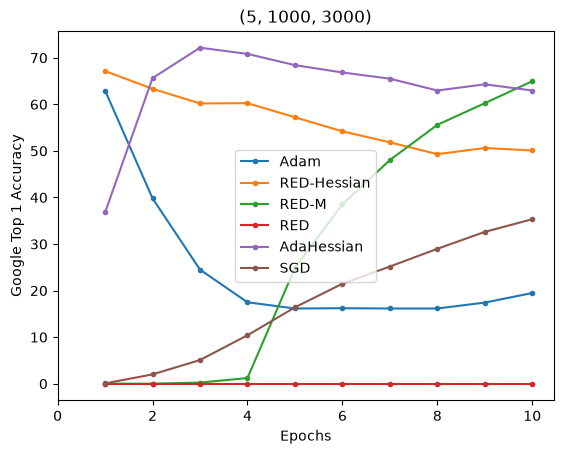

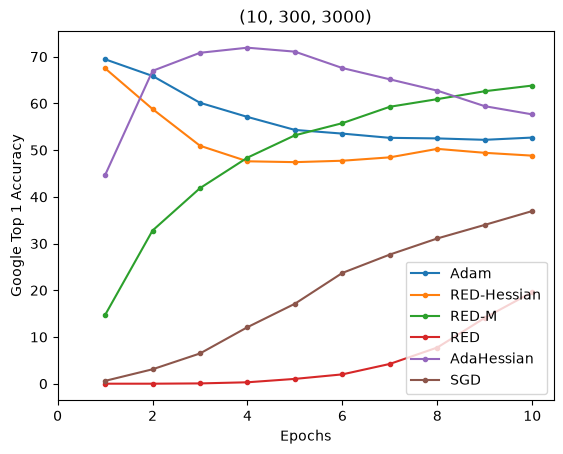

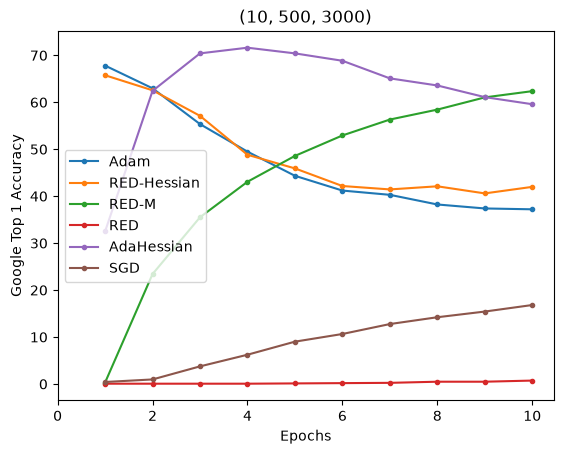

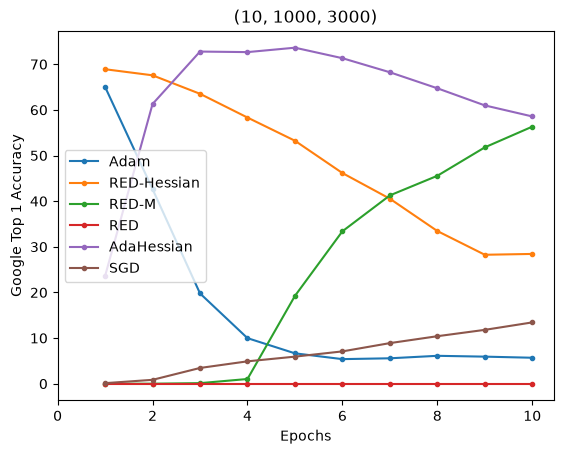

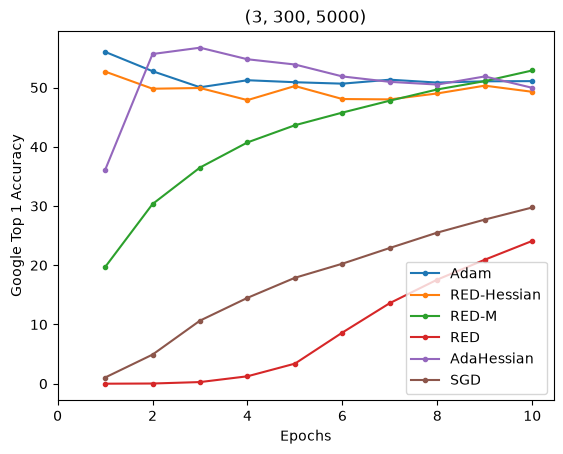

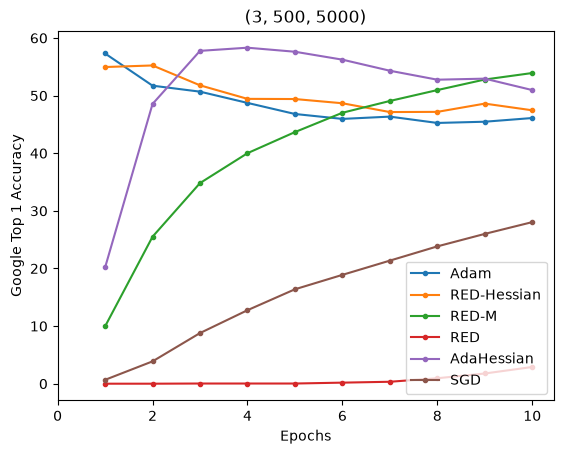

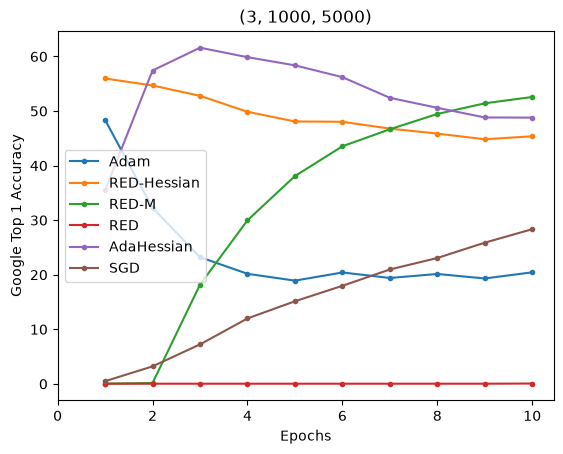

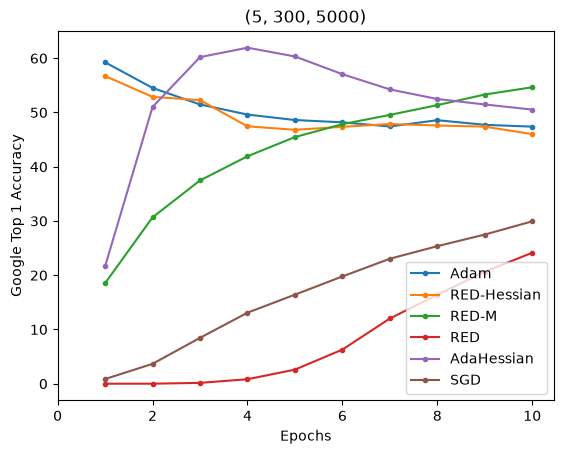

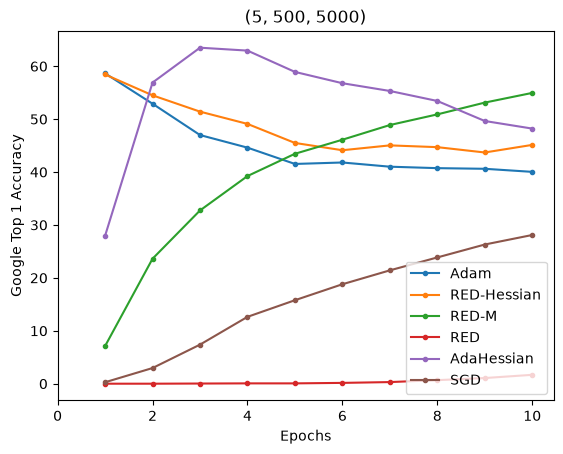

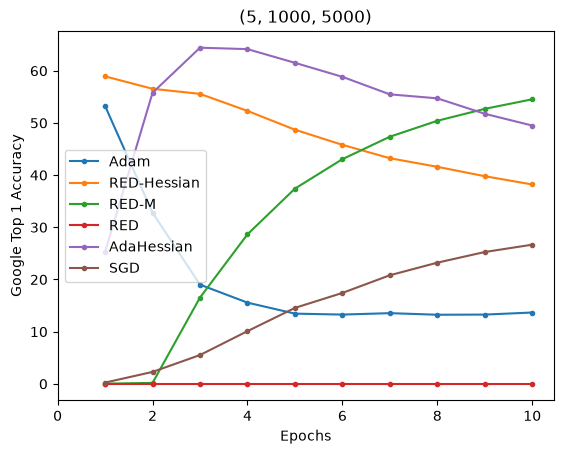

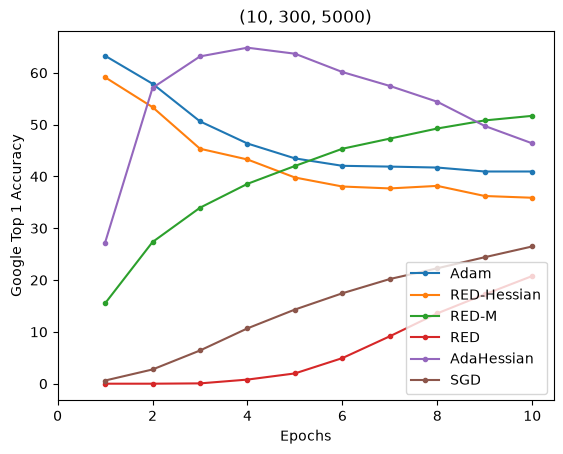

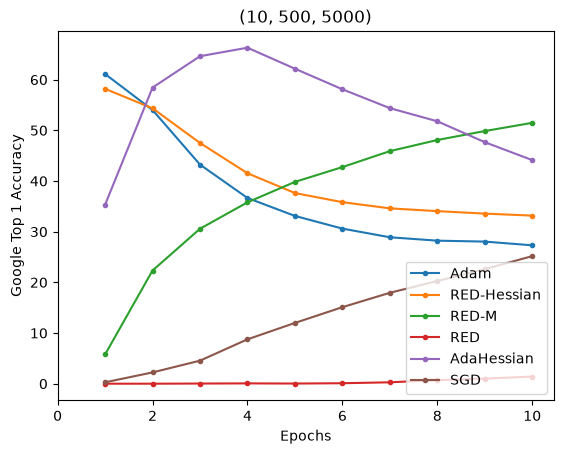

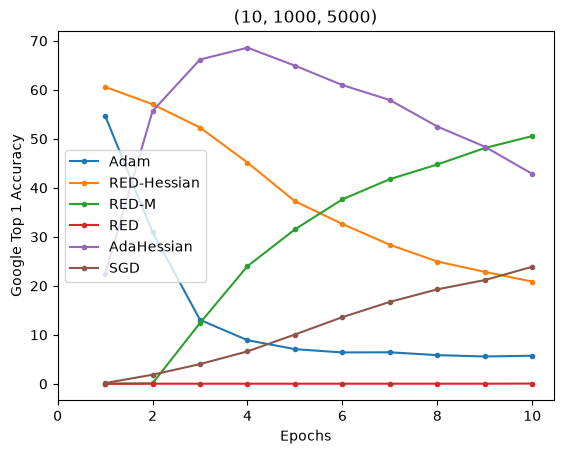

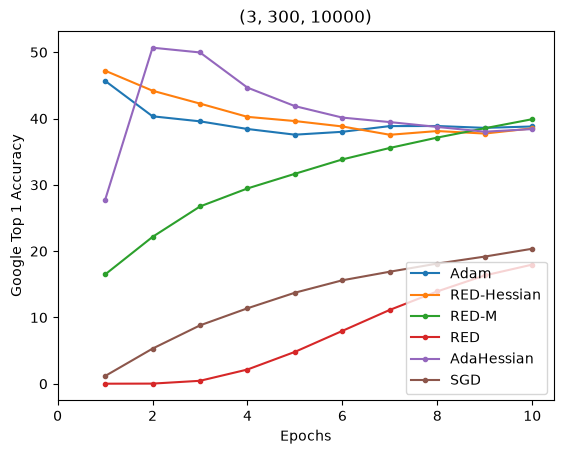

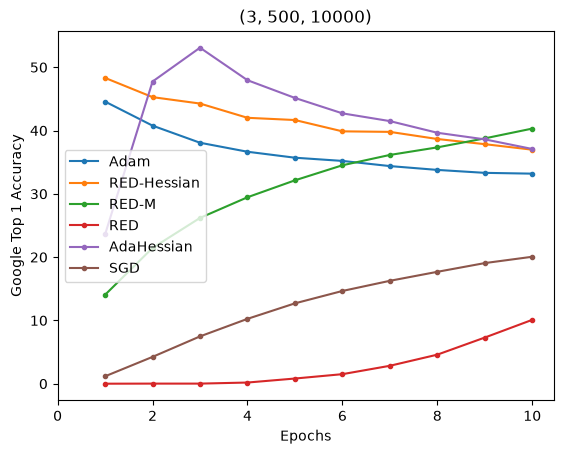

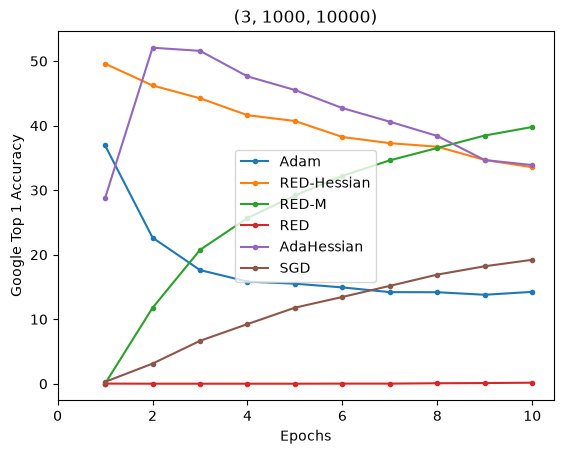

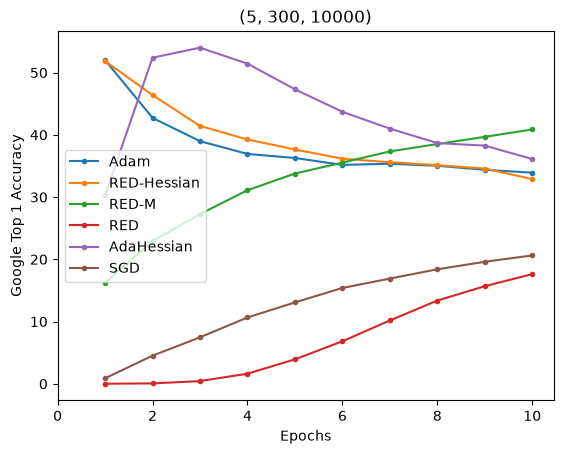

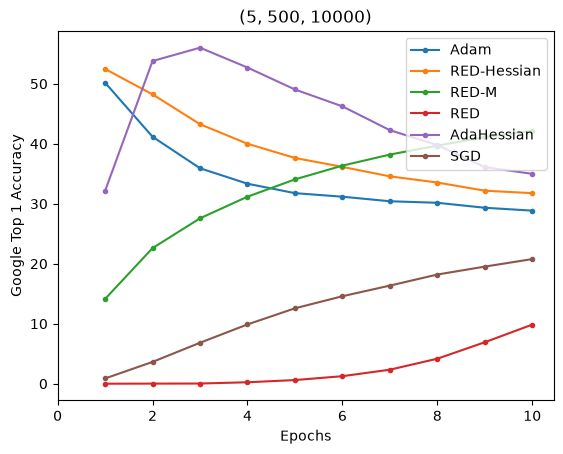

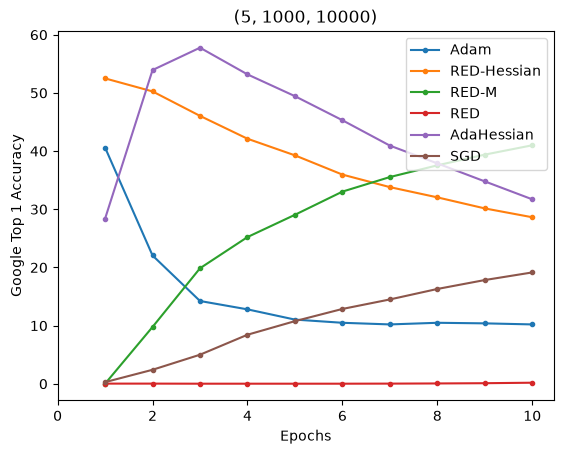

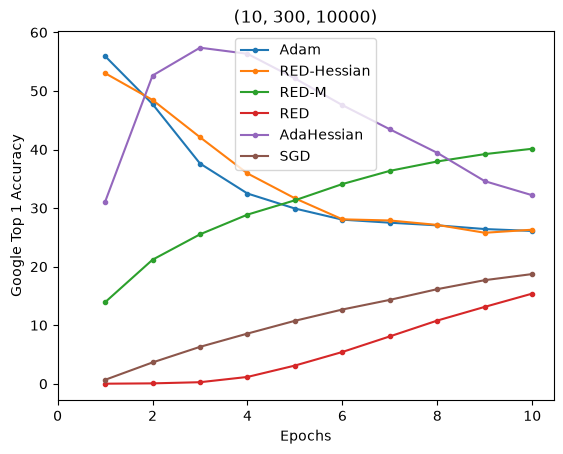

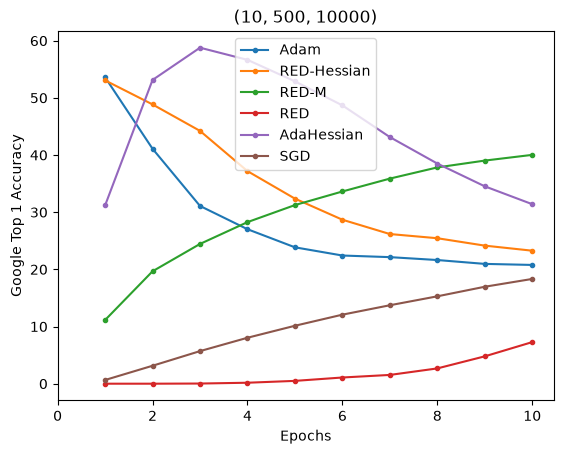

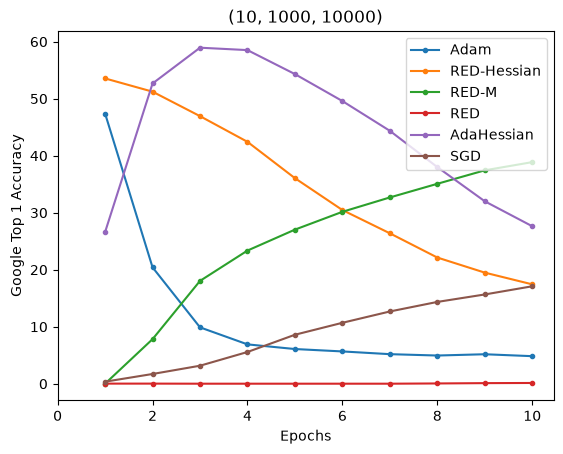

In [15]:
import itertools

print('done')
display = {"sgd": "SGD", "red": "RED", "redm": "RED-M", "adahessian": "AdaHessian", "adam": "Adam", "redhessian": "RED-Hessian"}
rlabel = {'google1': 'Google Top 1 Accuracy'}

windows = [3, 5, 10]
latent_dim = [300, 500, 1000]
vocab_szs = [3000, 5000, 10000]
optimizers = ['adam', 'redhessian', 'redm', 'red', 'adahessian', 'sgd']

def graph(res, time=False):
    for cur_vocab_sz, window, dim in itertools.product(vocab_szs, windows, latent_dim):
        for optim in optimizers:
            for i in range(10):
                results[(optim, window, dim, cur_vocab_sz)]['google1'][i] = results[(optim, window, dim, cur_vocab_sz)]['google1'][i]
            plt.plot(range(1, 11), results[(optim, window, dim, cur_vocab_sz)]['google1'], label=display[optim], marker="o", markersize=3)
        plt.xlabel("Epochs")
        plt.ylabel(f"{rlabel[res]}")
        plt.title(f"{(window, dim, cur_vocab_sz)}")
        plt.legend()
        plt.xticks(range(0, 11, 2))
        plt.show()

graph('google1')

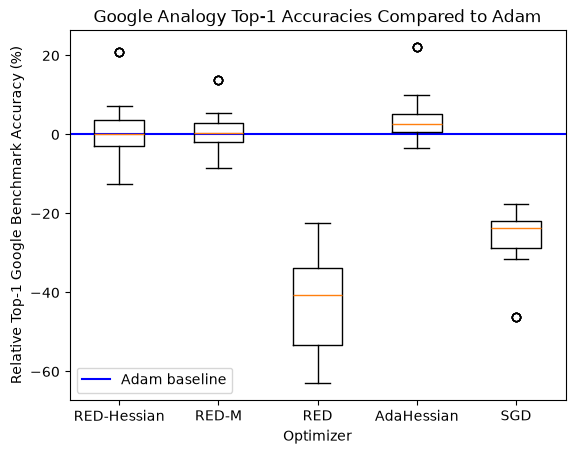

In [17]:
ref = 'adam'
benchmark = 'google1'

score = {}
for ((optim, window, dim, vocab), res) in results.items():
    best = int(onp.argmin([float(loss) for loss in res['test_loss']]))
    score[(optim, window, dim, vocab)] = res[benchmark][best]

non_ref = [o for o in optimizers if o != ref]
diffs = {o: [] for o in non_ref}
for optim in non_ref:
    for (optim, window, dim, vocab) in score:
        if optim != ref:
            diffs[optim].append(score[(optim, window, dim, vocab)] - score[(ref, window, dim, vocab)])

diffs_lst = [diffs[o] for o in non_ref]

plt.axhline(0, color='blue', label=f"{display[ref]} baseline")
plt.boxplot(diffs_lst, tick_labels=[display[o] for o in non_ref])
plt.ylabel(f"Relative Top-1 Google Benchmark Accuracy (%)")
plt.xlabel("Optimizer")
plt.title("Google Analogy Top-1 Accuracies Compared to Adam")
plt.legend()
plt.show()